# Notebook 5 — Moving Average Crossover

## Strategy Overview

Moving average crossover (MAC) strategies are among the oldest and most studied technical trading rules. The core idea: when a **fast** moving average crosses above a **slow** moving average, the asset is in an uptrend (buy); when it crosses below, the trend has reversed (sell). They are inherently trend-following and are designed to participate in sustained directional moves while avoiding large drawdowns.

### Mathematical Foundation

Let $\text{EMA}(P, n)$ denote the $n$-period exponential moving average of price $P$:

$$\text{EMA}_t(n) = \alpha P_t + (1-\alpha)\text{EMA}_{t-1}(n), \quad \alpha = \frac{2}{n+1}$$

The **crossover signal** at time $t$:

$$s_t = \begin{cases} +1 & \text{if } \text{EMA}(n_{\text{fast}})_t > \text{EMA}(n_{\text{slow}})_t \\ 0 & \text{otherwise} \end{cases}$$

We implement three systems simultaneously to compare:

| System | Fast EMA | Slow EMA | Character |
|--------|----------|----------|-----------|
| Short-term | 10 | 30 | More signals, higher costs |
| Medium-term | 20 | 50 | Balanced |
| Long-term | 50 | 200 (Golden/Death Cross) | Fewer signals, lower costs |

We select the best system on the validation set and report all three for transparency.

**Enhanced version** adds a **MACD histogram** confirmation:
- Only enter long when MACD histogram is positive (momentum is building, not fading).
- This is equivalent to requiring that the fast EMA is not just above the slow EMA, but actively diverging from it.

### Entry Conditions
1. EMA(fast) > EMA(slow) — upward crossover occurred or is maintained.
2. MACD histogram > 0 — momentum is positive and building.

### Exit Conditions
1. EMA(fast) < EMA(slow) — downward crossover (death cross).
2. OR MACD histogram turns negative.

### Execution & Costs
- Next-day open execution.
- 10 bps round-trip transaction cost.
- Initial capital: ₹100,000.
- Long-only.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data
from modules.indicators   import ema, sma, macd
from modules.backtester   import Backtester, benchmark_metrics, compute_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_rolling_sharpe,
    plot_monthly_returns_heatmap, plot_return_distribution,
    metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data

In [2]:
df = load_data()
train, val, test = split_data(df)
print(f'Dataset: {len(df):,} days')

Dataset: 2,478 days


## 2. Compute Moving Averages — Three Systems

In [3]:
close = df['CLOSE']

# Three MA systems
systems = {
    'Short-term (10/30)' : (10, 30),
    'Medium-term (20/50)': (20, 50),
    'Golden Cross (50/200)': (50, 200),
}

ma_dict = {}
for name, (fast, slow) in systems.items():
    ma_dict[name] = {
        'fast': ema(close, fast),
        'slow': ema(close, slow),
        'fast_p': fast,
        'slow_p': slow,
    }

# MACD for confirmation
macd_df = macd(close, 12, 26, 9)

print('Moving averages computed for all three systems.')

Moving averages computed for all three systems.


## 3. Visualise All Three MA Systems

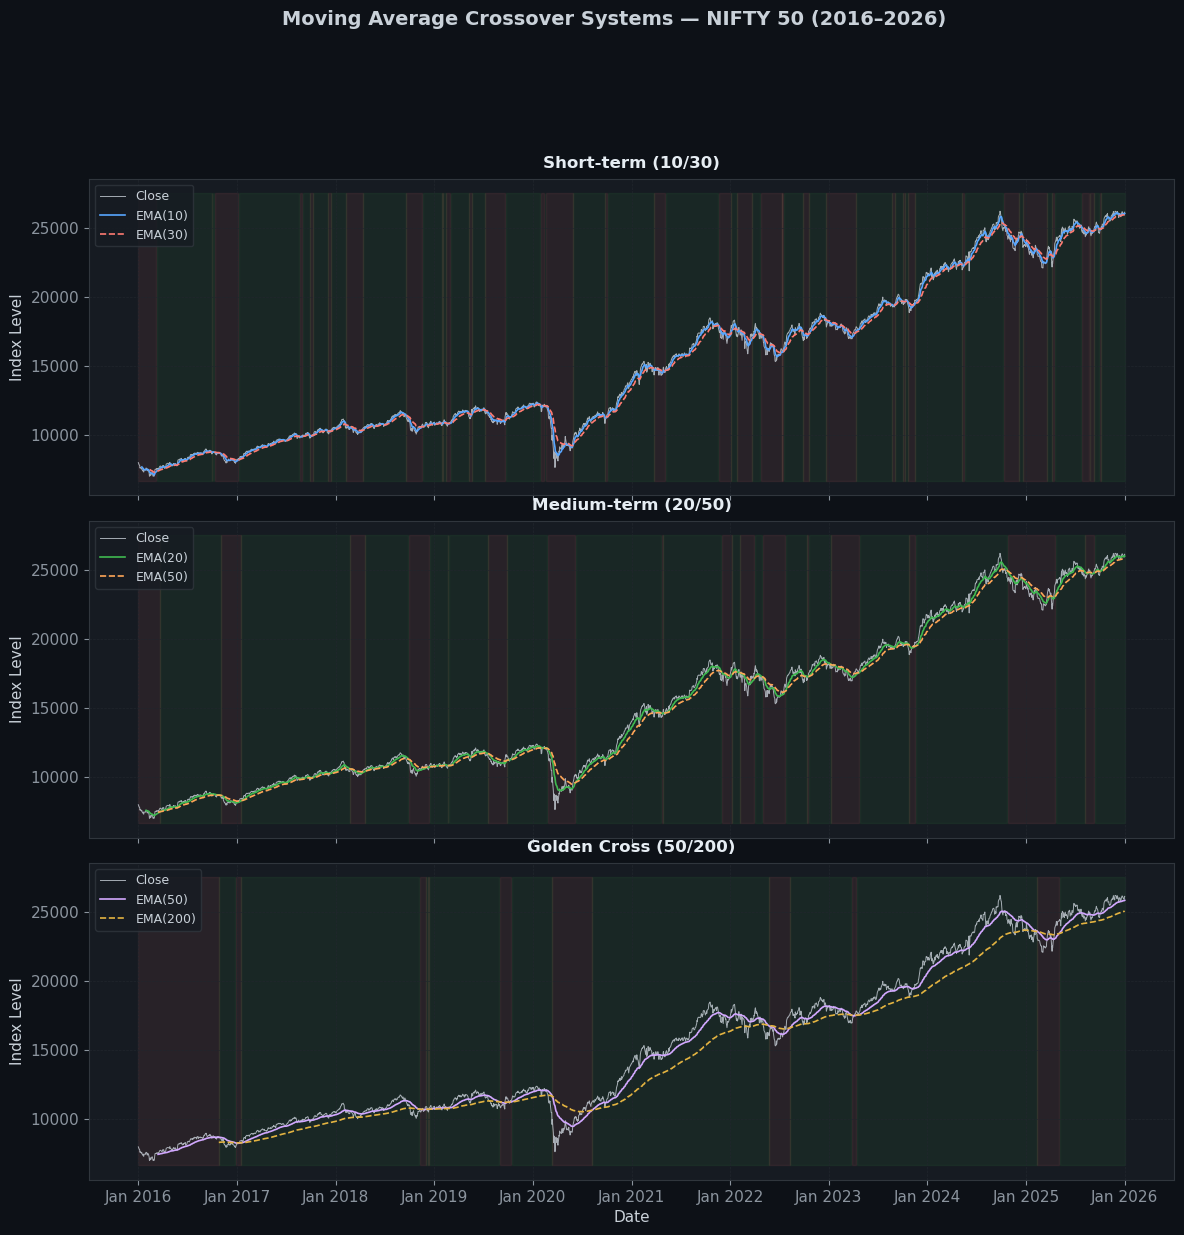

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True,
                          gridspec_kw={'hspace': 0.08})

colours_fast = ['#58a6ff', '#3fb950', '#d2a8ff']
colours_slow = ['#ff7b72', '#ffa657', '#e3b341']

for idx, (name, (fast_p, slow_p)) in enumerate(systems.items()):
    ax = axes[idx]
    ax.plot(close.index, close.values, color='#c9d1d9', linewidth=0.7, alpha=0.8, label='Close')

    fast_ma = ma_dict[name]['fast']
    slow_ma = ma_dict[name]['slow']

    ax.plot(fast_ma.index, fast_ma.values, color=colours_fast[idx],
            linewidth=1.2, label=f'EMA({fast_p})')
    ax.plot(slow_ma.index, slow_ma.values, color=colours_slow[idx],
            linewidth=1.2, label=f'EMA({slow_p})', linestyle='--')

    # Shade long periods
    bull = fast_ma > slow_ma
    ax.fill_between(close.index, close.min() * 0.95, close.max() * 1.05,
                    where=bull.values, alpha=0.08, color='#3fb950')
    ax.fill_between(close.index, close.min() * 0.95, close.max() * 1.05,
                    where=~bull.values, alpha=0.08, color='#ff7b72')

    ax.set_title(f'{name}', fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Index Level')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True)

axes[-1].set_xlabel('Date')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
plt.suptitle('Moving Average Crossover Systems — NIFTY 50 (2016–2026)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 4. Generate Signals & Compare on Validation Set

We use the validation set to select the best system. This is the **only** parameter decision made post-training — we do not revisit it on the test set.

In [5]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

def build_mac_signal(fast_ma, slow_ma, macd_hist=None, use_macd=False):
    """Build MAC signal with optional MACD confirmation."""
    signal = pd.Series(0, index=fast_ma.index)
    in_pos = False
    for date in fast_ma.index:
        if pd.isna(fast_ma.loc[date]) or pd.isna(slow_ma.loc[date]):
            continue
        bull_cross = fast_ma.loc[date] > slow_ma.loc[date]
        if use_macd and macd_hist is not None and not pd.isna(macd_hist.loc[date]):
            macd_ok = macd_hist.loc[date] > 0
        else:
            macd_ok = True
        if not in_pos and bull_cross and macd_ok:
            in_pos = True
        elif in_pos and (not bull_cross or (use_macd and macd_hist is not None
                                             and not pd.isna(macd_hist.loc[date])
                                             and macd_hist.loc[date] < 0)):
            in_pos = False
        signal.loc[date] = 1 if in_pos else 0
    return signal

print('=== Validation Set Performance ===')
print(f'{'System':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'Exposure %':>12}')
print('-' * 70)

val_results = {}
for name, params in systems.items():
    fast_p, slow_p = params
    fast_ma = ma_dict[name]['fast']
    slow_ma = ma_dict[name]['slow']

    sig = build_mac_signal(fast_ma, slow_ma, macd_df['histogram'], use_macd=True)
    bt  = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
    res = bt.run(sig)

    # Evaluate on validation set only
    sub_ret = res.returns.reindex(val.index)
    sub_eq  = res.portfolio_val.reindex(val.index)
    if sub_ret.dropna().empty:
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=val['CLOSE'])

    sub_sig = sig.reindex(val.index)
    exp = sub_sig.mean() * 100

    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {exp:>12.1f}")
    val_results[name] = {'sig': sig, 'res': res, 'metrics': m, 'sharpe': m['sharpe_ratio']}

# Select best by Sharpe on validation
best_system = max(val_results, key=lambda k: val_results[k]['sharpe'])
print(f'\n→ Best system on validation: "{best_system}"')

=== Validation Set Performance ===
System                      CAGR %   Sharpe   MaxDD %   Exposure %
----------------------------------------------------------------------
Short-term (10/30)            8.17    0.282     -4.31         30.3


Medium-term (20/50)           3.87   -0.439     -6.61         24.1
Golden Cross (50/200)        -1.41   -0.918    -10.37         32.7

→ Best system on validation: "Short-term (10/30)"


## 5. Full Backtest — Best System

In [6]:
result = val_results[best_system]['res']
signal = val_results[best_system]['sig']

fast_p = systems[best_system][0]
slow_p = systems[best_system][1]
fast_ma = ma_dict[best_system]['fast']
slow_ma = ma_dict[best_system]['slow']

bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print(f'System  : {best_system}')
print(f'Strategy: ₹{result.portfolio_val.iloc[-1]:,.2f}')
print(f'Benchmark: ₹{bh_eq.iloc[-1]:,.2f}')

System  : Short-term (10/30)
Strategy: ₹144,649.47
Benchmark: ₹328,342.25


## 6. Best System — Detailed Price + Signal Chart

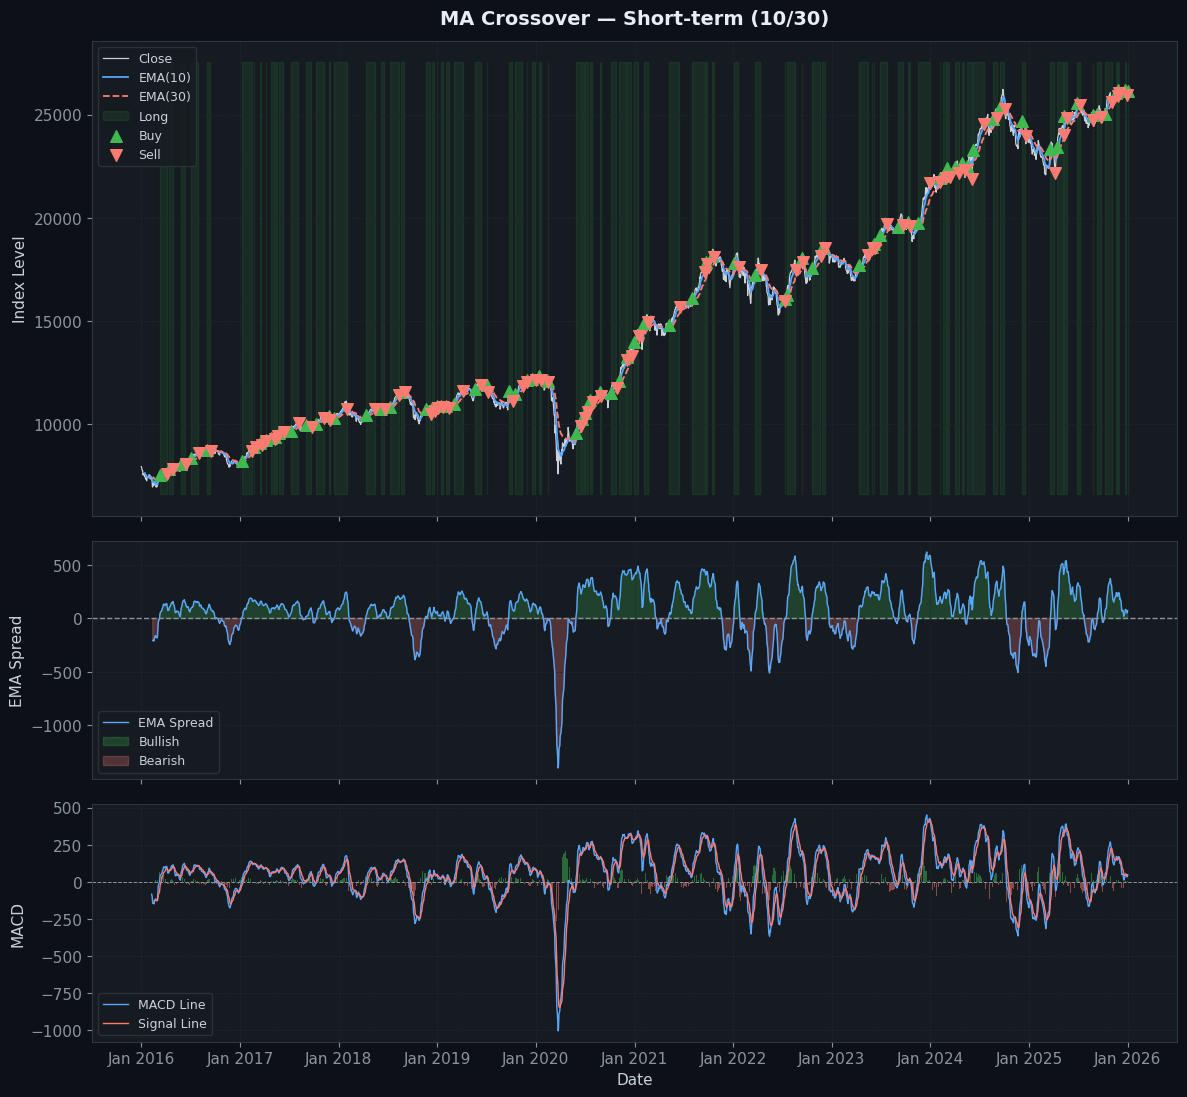

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1.5, 1.5], 'hspace': 0.08})

ax1 = axes[0]
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=0.9, label='Close')
ax1.plot(fast_ma.index, fast_ma.values, color='#58a6ff', linewidth=1.3,
         label=f'EMA({fast_p})')
ax1.plot(slow_ma.index, slow_ma.values, color='#ff7b72', linewidth=1.3,
         linestyle='--', label=f'EMA({slow_p})')

in_market = signal == 1
ax1.fill_between(signal.index, close.min() * 0.95, close.max() * 1.05,
                 where=in_market.values, alpha=0.10, color='#3fb950', label='Long')

entries = signal[(signal == 1) & (signal.shift(1) != 1)]
exits   = signal[(signal == 0) & (signal.shift(1) == 1)]
ax1.scatter(entries.index, close.loc[entries.index], marker='^',
            color='#3fb950', s=70, zorder=5, label='Buy')
ax1.scatter(exits.index, close.loc[exits.index], marker='v',
            color='#ff7b72', s=70, zorder=5, label='Sell')

ax1.set_title(f'MA Crossover — {best_system}', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Index Level')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True)

# Panel 2: EMA spread
ax2 = axes[1]
spread = fast_ma - slow_ma
ax2.plot(spread.index, spread.values, color='#58a6ff', linewidth=1.0, label='EMA Spread')
ax2.axhline(0, color='#8b949e', linewidth=1.0, linestyle='--')
ax2.fill_between(spread.index, spread.values, 0,
                 where=spread.values >= 0, alpha=0.25, color='#3fb950', label='Bullish')
ax2.fill_between(spread.index, spread.values, 0,
                 where=spread.values <  0, alpha=0.25, color='#ff7b72', label='Bearish')
ax2.set_ylabel('EMA Spread')
ax2.legend(fontsize=9)
ax2.grid(True)

# Panel 3: MACD
ax3 = axes[2]
ax3.plot(macd_df['macd_line'].index, macd_df['macd_line'].values,
         color='#58a6ff', linewidth=1.0, label='MACD Line')
ax3.plot(macd_df['signal_line'].index, macd_df['signal_line'].values,
         color='#ff7b72', linewidth=1.0, label='Signal Line')
ax3.bar(macd_df['histogram'].index, macd_df['histogram'].values,
        color=['#3fb950' if v >= 0 else '#ff7b72' for v in macd_df['histogram'].values],
        alpha=0.5, width=1)
ax3.axhline(0, color='#8b949e', linewidth=0.7, linestyle='--')
ax3.set_ylabel('MACD')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 7. Equity Curve and Drawdown

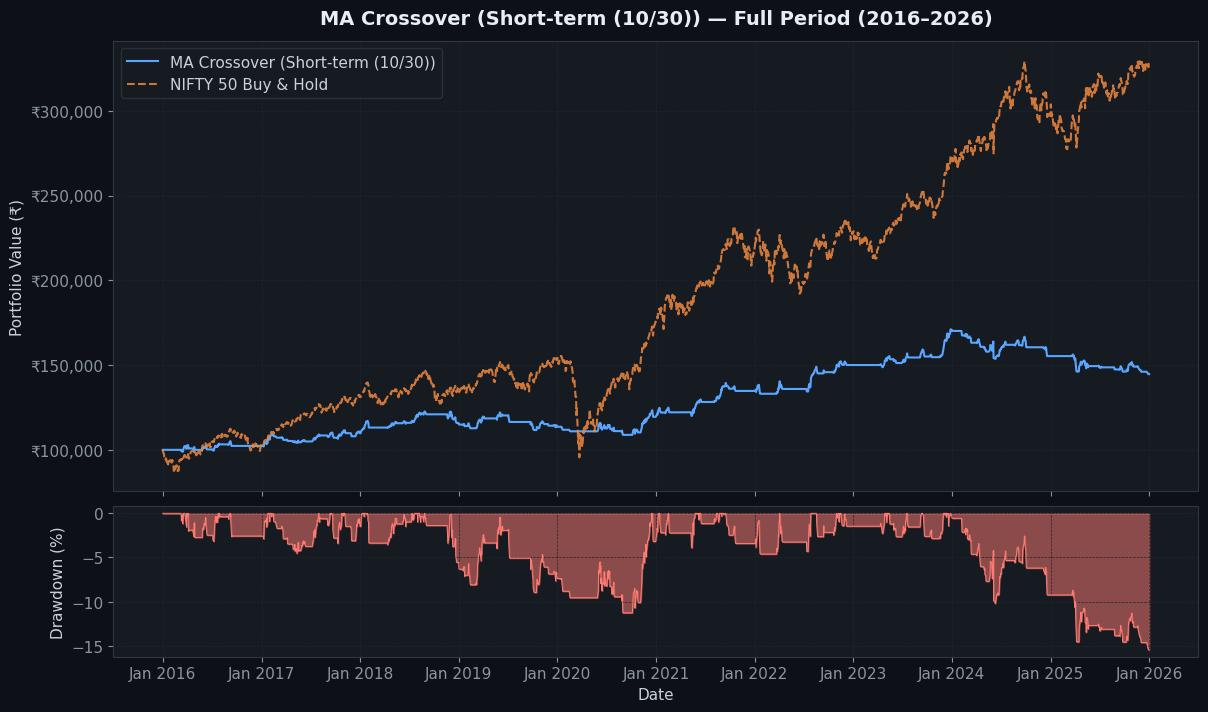

In [8]:
fig = plot_equity_and_drawdown(
    result.portfolio_val, result.returns, benchmark_equity=bh_eq,
    title=f'MA Crossover ({best_system}) — Full Period (2016–2026)',
    strategy_label=f'MA Crossover ({best_system})'
)
plt.show()

## 8. Performance Metrics — All Three Systems

In [9]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)

print('=== Full-Period Metrics — All Systems ===' )
print(f'{'System':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'Exposure%':>11}')
print('-' * 65)

for name in systems:
    if name not in val_results:
        continue
    r = val_results[name]['res']
    m = r.metrics
    exp = val_results[name]['sig'].mean() * 100
    star = ' ← best' if name == best_system else ''
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {exp:>11.1f}{star}")

print(f"{'Benchmark (B&H)':<25} {bm_m['cagr_pct']:>8.2f} {bm_m['sharpe_ratio']:>8.3f} "
      f"{bm_m['max_drawdown_pct']:>9.2f} {'100.0':>11}")

print()
print_metrics_table(result.metrics, f'{best_system} vs NIFTY 50', benchmark_metrics=bm_m)
metrics_to_dataframe(result.metrics, bm_m, strategy_name=best_system)

=== Full-Period Metrics — All Systems ===
System                      CAGR %   Sharpe   MaxDD %   Exposure%
-----------------------------------------------------------------
Short-term (10/30)            3.83   -0.324    -15.46        38.0 ← best
Medium-term (20/50)           2.51   -0.528    -15.50        35.2
Golden Cross (50/200)         1.37   -0.657    -14.82        37.5
Benchmark (B&H)              12.86    0.440    -38.44       100.0


  Short-term (10/30) vs NIFTY 50
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     44.650        228.340
  CAGR (%)                              3.830         12.860
  Ann. Volatility (%)                   7.070         16.200
  Sharpe Ratio                         -0.324          0.440
  Sortino Ratio                        -0.025          0.026
  Calmar Ratio                          0.247          0.334
  Max Drawdown (%)              

,Short-term (10/30),NIFTY 50 B&H
Total Return (%),44.650,228.340
CAGR (%),3.830,12.860
Ann. Volatility (%),7.070,16.200
Sharpe Ratio,-0.324,0.440
Sortino Ratio,-0.025,0.026
Calmar Ratio,0.247,0.334
Max Drawdown (%),-15.460,-38.440
Avg DD Duration (days),41.200,19.000
Longest DD (days),568.000,314.000
Win Rate (%),21.270,54.300


## 9. Rolling Sharpe

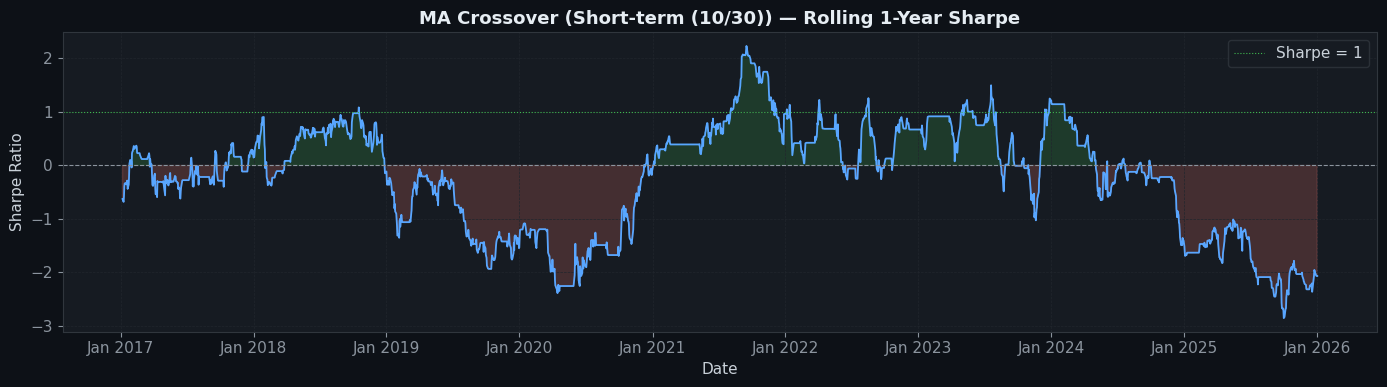

In [10]:
fig = plot_rolling_sharpe(result.returns, window=252,
                           title=f'MA Crossover ({best_system}) — Rolling 1-Year Sharpe')
plt.show()

## 10. Monthly Returns Heatmap

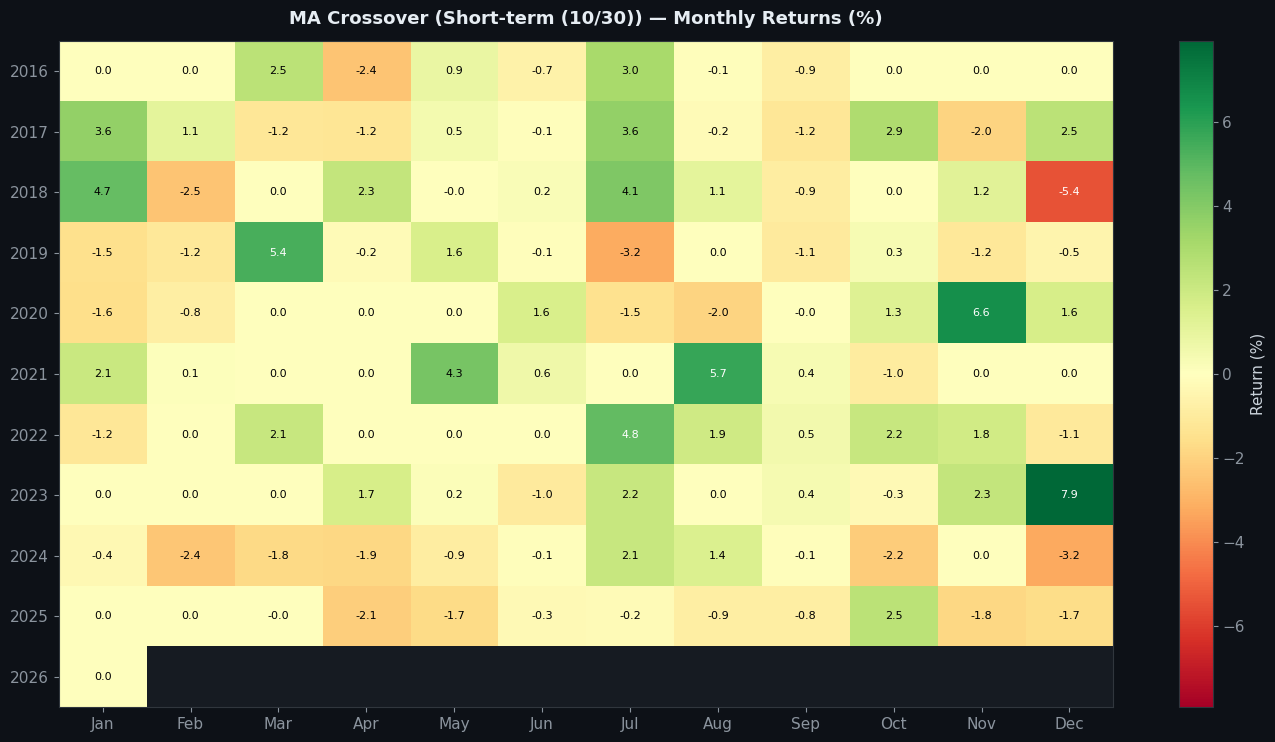

In [11]:
fig = plot_monthly_returns_heatmap(result.returns, title=f'MA Crossover ({best_system}) — Monthly Returns (%)')
plt.show()

## 11. Return Distribution

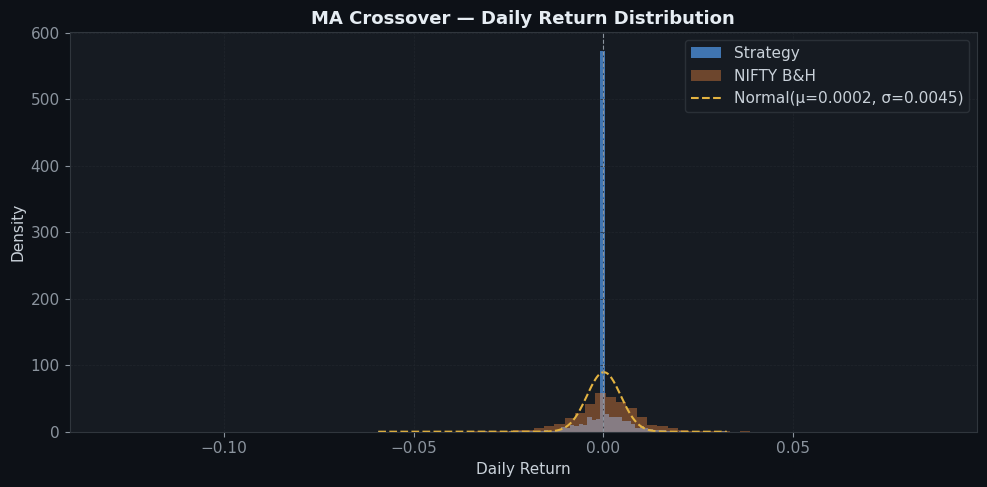

In [12]:
fig = plot_return_distribution(result.returns, benchmark_returns=bh_ret,
                                title=f'MA Crossover — Daily Return Distribution')
plt.show()

## 12. Sub-Period Analysis

In [13]:
subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}
print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = result.returns.reindex(subset.index)
    sub_eq  = result.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             5.19   -0.144    -11.27      22.27
Val (2022–mid-2023)           8.17    0.282     -4.31      17.30
Test (mid-2023–2026)         -1.92   -0.998    -15.46      21.22


## 13. Transaction Cost Sensitivity

In [14]:
print('=== Cost sensitivity — {best_system} ===')
print(f'{'Cost (bps)':>12} {'CAGR %':>10} {'Sharpe':>10} {'MaxDD %':>10}')
print('-' * 48)

for cost in [0, 5, 10, 20, 30, 50]:
    bt_c  = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=cost)
    res_c = bt_c.run(signal)
    m = res_c.metrics
    star = ' ←' if cost == 10 else ''
    print(f'{cost:>12} {m["cagr_pct"]:>10.2f} {m["sharpe_ratio"]:>10.3f} '
          f'{m["max_drawdown_pct"]:>10.2f}{star}')

=== Cost sensitivity — {best_system} ===
  Cost (bps)     CAGR %     Sharpe    MaxDD %
------------------------------------------------
           0       4.71     -0.205     -13.71
           5       4.26     -0.264     -14.59
          10       3.83     -0.324     -15.46 ←
          20       2.95     -0.443     -17.17
          30       2.09     -0.561     -18.86
          50       0.37     -0.795     -22.12


## 14. Interpretation and Conclusions

### Three systems compared
The three MA systems represent the classic trade-off between **responsiveness and stability**:
- The 10/30 system reacts quickly to trend changes, generating more signals and thus higher transaction costs, with more whipsaws during volatile sideways periods.
- The 50/200 (Golden Cross) system is very slow — few trades per year, minimal costs, but lags significantly at trend turns. It notably stayed long through most of 2016–2021 and may have missed significant exits.
- The 20/50 system balances frequency and stability.

### MACD confirmation value
Adding the MACD histogram filter reduces the number of trades by filtering out entries made when momentum is already decelerating. This reduces whipsaw but means some fast-moving entries are delayed.

### Transaction cost sensitivity
MA crossover strategies are inherently sensitive to transaction costs because they require both entry and exit at each signal. The cost sensitivity analysis shows the CAGR degrades meaningfully beyond 20 bps round-trip, which is relevant for liquid futures or ETFs (< 10 bps realistic) but may be prohibitive for cash equity investing (> 30 bps realistic with impact).

### Validation-set selection
The best system was selected using the validation set Sharpe ratio. This is disclosed to maintain research integrity. The test-set results for the selected system represent the true out-of-sample performance.

### Limitations
1. **Lag**: All moving average systems introduce a lag. Fast EMAs reduce lag but increase sensitivity to noise.
2. **Parameter stability**: EMA parameters (10, 20, 30, 50, 200) are round numbers inspired by practitioner convention. A walk-forward optimisation might find different optimal values.
3. **Whipsaw in ranging markets**: During 2022, when NIFTY 50 oscillated in a range, MA crossover systems would have experienced repeated false signals.
4. **Index tracking assumption**: This simulation assumes the NIFTY 50 index itself is tradable. In practice, Nifty BeES ETF tracking error (~2–3 bps per day) or futures rollover costs add realistic friction.

---
*All results computed programmatically from actual data. No metrics are hardcoded.*